In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

In [2]:
df_onecoin = pd.read_csv('reddit_sentiment_data_Onecoin_2024.csv')
df_ftx = pd.read_csv('reddit_sentiment_data_FTX_2024.csv')
df_celsius = pd.read_csv('reddit_sentiment_data_Celsius_2024.csv')
df_centra = pd.read_csv('reddit_sentiment_data_Centra_2024.csv')
# df_bitcoin = pd.read_csv('bitcointalk_scam_data.csv')

In [3]:
# df_bitcoin.head()

In [4]:
df_onecoin["source"] = "OneCoin"
df_ftx["source"] = "FTX"
df_centra["source"] = "Centra"
df_celsius["source"] = "Celsius"
# df_bitcoin["source"] = "BitcoinTalk"

In [5]:
# Make sure BitcoinTalk is included here
scam_colors = {
    'OneCoin':    'blue',
    'FTX':        'orange',
    'Centra':     'green',
    'Celsius':    'red',
    'BitcoinTalk': 'purple'   # ← add this
}

In [6]:
#  standardize time column
def standardize_time(df):
    df['timestamp_utc'] = pd.to_datetime(df['timestamp_utc'], errors='coerce')
    df["year_month"] = df['timestamp_utc'].dt.to_period('M')
    return df

df_onecoin = standardize_time(df_onecoin)
df_ftx = standardize_time(df_ftx)
df_centra = standardize_time(df_centra)
df_celsius = standardize_time(df_celsius)
# df_bitcoin = standardize_time(df_bitcoin)

In [7]:
def clean_text(text):
    text = text.lower()
    # text = re.sub(r"http\S+", "", text)   # remove URLs
    text = re.sub(r"[^a-z\s]", "", text)  # remove punctuation
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [8]:
df_all = pd.concat([df_onecoin, df_ftx, df_centra, df_celsius], ignore_index=True)  

In [9]:
# Step 1: count URLs on the original raw text first
df_all['url_count'] = df_all['text'].str.count(r'https?://\S+')

# Step 2: THEN apply cleaning as before
df_all['cleaned_text'] = df_all['text'].fillna('').astype(str).apply(clean_text)

In [10]:
df_all.count()

id               195556
subreddit        195556
type             195556
author           195556
timestamp_utc    195556
text             195550
parent_id        192462
source           195556
year_month       195556
url_count        195550
cleaned_text     195556
dtype: int64

In [11]:
df_all.head()

,id,subreddit,type,author,timestamp_utc,text,parent_id,source,year_month,url_count,cleaned_text
0,7r6chx,cryptocurrency,post,PM_Poutine,2018-01-18 02:04:30,Here is a list of crypto ponzi schemes and peo...,NaN,OneCoin,2018-01,2.0,here is a list of crypto ponzi schemes and peo...
1,dsukfjh,cryptocurrency,comment,[deleted],2018-01-18 02:21:43,"Great, I got 4 hours ago into this whole topic...",t3_7r6chx,OneCoin,2018-01,0.0,great i got hours ago into this whole topic an...
2,dsukd60,cryptocurrency,comment,BamboozleVictim,2018-01-18 02:20:27,"Theres one that just finished their ICO, BitAI...",t3_7r6chx,OneCoin,2018-01,0.0,theres one that just finished their ico bitai ...
3,dsumrvh,cryptocurrency,comment,[deleted],2018-01-18 03:07:24,Whilst not on his youtube as far as i know Moe...,t3_7r6chx,OneCoin,2018-01,0.0,whilst not on his youtube as far as i know moe...
4,dsukssd,cryptocurrency,comment,krypt0maniac,2018-01-18 02:29:00,This is a great resource. Thanks for taking th...,t3_7r6chx,OneCoin,2018-01,0.0,this is a great resource thanks for taking the...


In [12]:
# text-based features
df_all['text_length'] = df_all['cleaned_text'].apply(len)
df_all['word_count'] = df_all['cleaned_text'].apply(lambda x: len(x.split()))
df_all['url_count'] = df_all['cleaned_text'].str.count('http')

In [13]:
# scam keyword flags
scam_keywords = ['scam', 'double', 'fake', 'wallet drained', 'phishing', 'risk-free', 'urgent', 'impersonation', 'no loss','limited time', 'secret',  'hack', 'malware', 'suspicious', 'unverified',  'investment opportunity', 'fraud', 'deceptive']
def contains_scam_keywords(text):
    return sum(1 for k in scam_keywords if k in text)

df_all['contains_scam_keywords'] = df_all['cleaned_text'].apply(contains_scam_keywords)
df_all.head()

,id,subreddit,type,author,timestamp_utc,text,parent_id,source,year_month,url_count,cleaned_text,text_length,word_count,contains_scam_keywords
0,7r6chx,cryptocurrency,post,PM_Poutine,2018-01-18 02:04:30,Here is a list of crypto ponzi schemes and peo...,NaN,OneCoin,2018-01,2,here is a list of crypto ponzi schemes and peo...,2789,373,1
1,dsukfjh,cryptocurrency,comment,[deleted],2018-01-18 02:21:43,"Great, I got 4 hours ago into this whole topic...",t3_7r6chx,OneCoin,2018-01,0,great i got hours ago into this whole topic an...,133,28,0
2,dsukd60,cryptocurrency,comment,BamboozleVictim,2018-01-18 02:20:27,"Theres one that just finished their ICO, BitAI...",t3_7r6chx,OneCoin,2018-01,0,theres one that just finished their ico bitai ...,196,31,0
3,dsumrvh,cryptocurrency,comment,[deleted],2018-01-18 03:07:24,Whilst not on his youtube as far as i know Moe...,t3_7r6chx,OneCoin,2018-01,0,whilst not on his youtube as far as i know moe...,161,30,1
4,dsukssd,cryptocurrency,comment,krypt0maniac,2018-01-18 02:29:00,This is a great resource. Thanks for taking th...,t3_7r6chx,OneCoin,2018-01,0,this is a great resource thanks for taking the...,160,29,0


In [14]:
# Metadata features
df_all['is_comment'] = df_all['type'].apply(lambda x: 1 if x == 'comment' else 0)
df_all['is_deleted_author'] = df_all['author'].apply(lambda x: 1 if x == '[deleted]' else 0)
df_all['hour'] = df_all['timestamp_utc'].dt.hour
df_all['day_of_week'] = df_all['timestamp_utc'].dt.dayofweek
df_all['date'] = df_all['timestamp_utc'].dt.date
df_all['year_month'] = df_all['timestamp_utc'].dt.to_period('M')
df_all['year'] = df_all['timestamp_utc'].dt.year
df_24_25 = df_all[df_all['year'].isin([2022,2023, 2024, 2025, 2026])]
df_24_25.head()

,id,subreddit,type,author,timestamp_utc,text,parent_id,source,year_month,url_count,cleaned_text,text_length,word_count,contains_scam_keywords,is_comment,is_deleted_author,hour,day_of_week,date,year
711,167j14k,cryptocurrency,post,pseudoHappyHippy,2023-09-01 21:03:31,"TIL that Ruja Ignatova, after founding a huge ...",NaN,OneCoin,2023-09,3,til that ruja ignatova after founding a huge f...,2579,431,3,0,0,21,4,2023-09-01,2023
712,jyq0uoz,cryptocurrency,comment,diarpiiiii,2023-09-01 21:13:41,Highly recommend the BBC podcast about this st...,t3_167j14k,OneCoin,2023-09,1,highly recommend the bbc podcast about this st...,127,12,0,1,0,21,4,2023-09-01,2023
713,jyr94mc,cryptocurrency,comment,djsimmy365,2023-09-02 02:36:59,"Holy cow, this whole story is insane and so di...",t3_167j14k,OneCoin,2023-09,0,holy cow this whole story is insane and so dis...,215,39,0,1,0,2,5,2023-09-02,2023
714,jyq19sn,cryptocurrency,comment,[deleted],2023-09-01 21:16:21,[deleted],t3_167j14k,OneCoin,2023-09,0,deleted,7,1,0,1,1,21,4,2023-09-01,2023
715,jyq2zet,cryptocurrency,comment,Dubznation300,2023-09-01 21:27:24,Who the hell gave her 4 billion,t3_167j14k,OneCoin,2023-09,0,who the hell gave her billion,29,6,0,1,0,21,4,2023-09-01,2023


In [15]:
print(df_all['year'].value_counts().sort_index())

year
2017      1752
2018      1524
2019       427
2020       916
2021     25057
2022    103969
2023     44746
2024     10220
2025      6945
Name: count, dtype: int64


In [16]:
# scam_count_year = df_all.groupby(['year', 'source']).size().reset_index(name='count')
# scam_count_year
count_24_25 = (
    df_24_25
    .groupby(['year_month', 'source'])
    .size()
    .reset_index(name='count')
)

count_24_25['year_month'] = count_24_25['year_month'].astype(str)

count_24_25.head()



,year_month,source,count
0,2022-01,Celsius,175
1,2022-01,Centra,5
2,2022-01,FTX,980
3,2022-01,OneCoin,3
4,2022-02,Celsius,1907


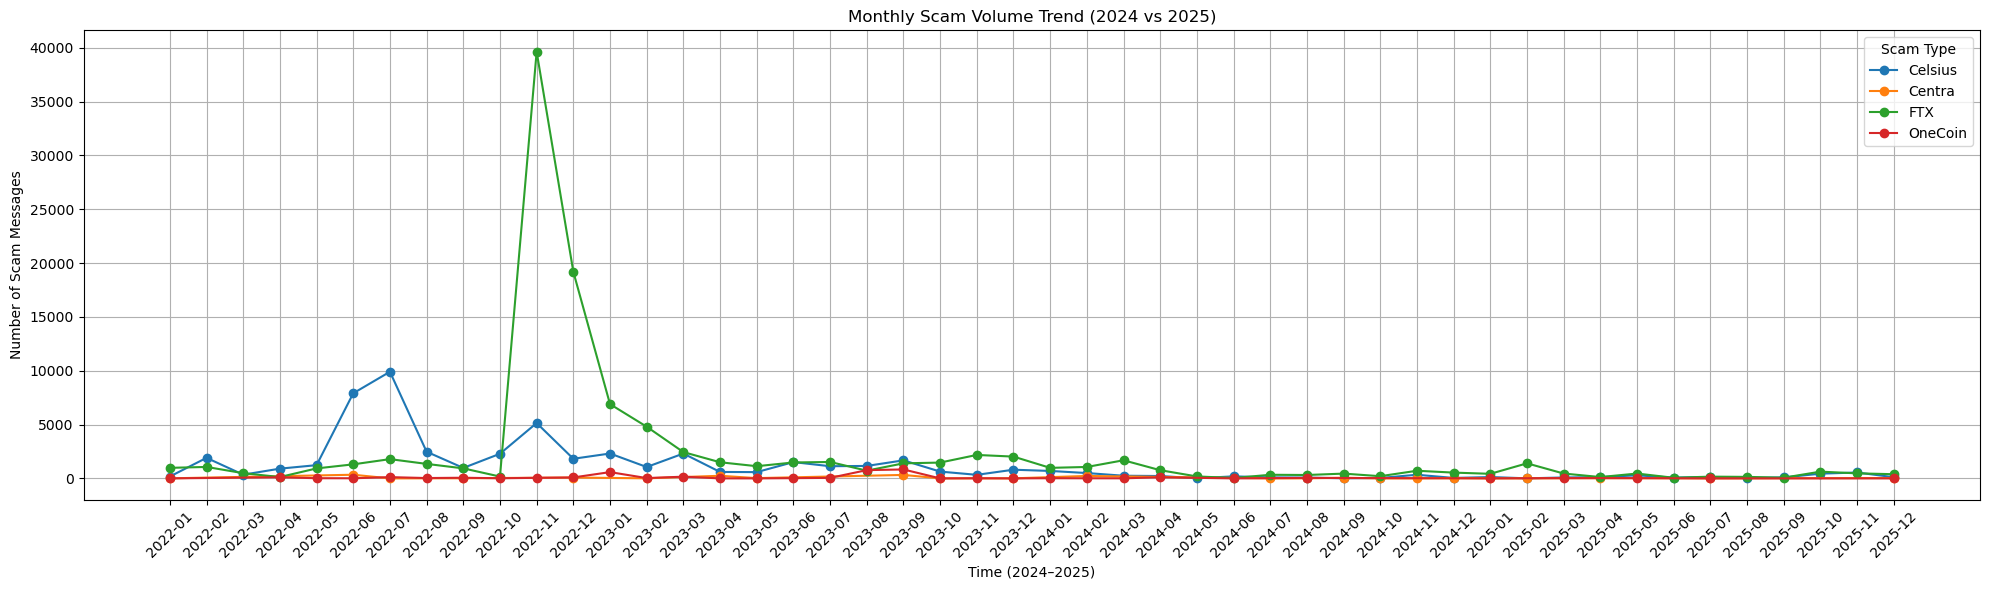

In [17]:
plt.figure(figsize=(20,6))

for scam in count_24_25['source'].unique():
    temp = count_24_25[count_24_25['source'] == scam]
    plt.plot(
        temp['year_month'],
        temp['count'],
        marker='o',
        label=scam
    )

plt.xlabel("Time (2024–2025)")
plt.ylabel("Number of Scam Messages")
plt.title("Monthly Scam Volume Trend (2024 vs 2025)")
plt.xticks(rotation=45)
plt.legend(title="Scam Type")
plt.grid(True)
plt.tight_layout()

In [18]:
def heuristic_score(text):
    text = str(text).lower()
    return sum(word in text for word in scam_keywords)

df_all["heuristic_score"] = df_all["text"].apply(heuristic_score)
df_all["heuristic_label"] = (df_all["heuristic_score"] >= 2).astype(int)
df_all.head()

,id,subreddit,type,author,timestamp_utc,text,parent_id,source,year_month,url_count,...,word_count,contains_scam_keywords,is_comment,is_deleted_author,hour,day_of_week,date,year,heuristic_score,heuristic_label
0,7r6chx,cryptocurrency,post,PM_Poutine,2018-01-18 02:04:30,Here is a list of crypto ponzi schemes and peo...,NaN,OneCoin,2018-01,2,...,373,1,0,0,2,3,2018-01-18,2018,1,0
1,dsukfjh,cryptocurrency,comment,[deleted],2018-01-18 02:21:43,"Great, I got 4 hours ago into this whole topic...",t3_7r6chx,OneCoin,2018-01,0,...,28,0,1,1,2,3,2018-01-18,2018,0,0
2,dsukd60,cryptocurrency,comment,BamboozleVictim,2018-01-18 02:20:27,"Theres one that just finished their ICO, BitAI...",t3_7r6chx,OneCoin,2018-01,0,...,31,0,1,0,2,3,2018-01-18,2018,0,0
3,dsumrvh,cryptocurrency,comment,[deleted],2018-01-18 03:07:24,Whilst not on his youtube as far as i know Moe...,t3_7r6chx,OneCoin,2018-01,0,...,30,1,1,1,3,3,2018-01-18,2018,1,0
4,dsukssd,cryptocurrency,comment,krypt0maniac,2018-01-18 02:29:00,This is a great resource. Thanks for taking th...,t3_7r6chx,OneCoin,2018-01,0,...,29,0,1,0,2,3,2018-01-18,2018,0,0


In [19]:
# Scam likelihood heuristic scoring
from sklearn.preprocessing import MinMaxScaler

# create needed columns first
df_all['long_text_flag'] = (df_all['text_length'] > 500).astype(int)
df_all['scam_keyword_count'] = df_all['contains_scam_keywords']  # align names

features = ['scam_keyword_count', 'url_count', 'is_deleted_author', 'long_text_flag']
scaler = MinMaxScaler()
df_all[features] = scaler.fit_transform(df_all[features])

df_all['scam_score'] = (
    0.4 * df_all['scam_keyword_count'] +
    0.2 * df_all['url_count'] +
    0.2 * df_all['is_deleted_author'] +
    0.2 * df_all['long_text_flag']
)

# Post must have a score > 0 AND meet a specific quantile
threshold = df_all[df_all['scam_score'] > 0]['scam_score'].median() # Quantile of ONLY non-zero scores
df_all['scam_likelihood'] = (df_all['scam_score'] > 0) & (df_all['scam_score'] >= threshold)
print("Scam Score Distribution:\n", df_all['scam_score'].value_counts().head())
print("\nCalculated Threshold:", df_all['scam_score'].quantile(0.75))
print("Class Counts:\n", df_all['scam_likelihood'].value_counts())


Scam Score Distribution:
 scam_score
0.000000    151066
0.200000     27879
0.057143      6698
0.000800      3238
0.257143      1860
Name: count, dtype: int64

Calculated Threshold: 0.0
Class Counts:
 scam_likelihood
False    162579
True      32977
Name: count, dtype: int64


In [20]:
# sentiment analysis
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer 
analyzer = SentimentIntensityAnalyzer()
df_all['sentiment'] = df_all['cleaned_text'].apply(lambda x: analyzer.polarity_scores(x)['compound'])

# -1 -> very negative
# 0 -> neutral
# 1 -> very positive

In [21]:
FEATURES = [
    'text_length',
    'word_count',
    'url_count',
    'contains_scam_keywords',
    'is_comment',
    'sentiment'
]
target = df_all[FEATURES]
labels = df_all['scam_likelihood']
df_all.head()

,id,subreddit,type,author,timestamp_utc,text,parent_id,source,year_month,url_count,...,day_of_week,date,year,heuristic_score,heuristic_label,long_text_flag,scam_keyword_count,scam_score,scam_likelihood,sentiment
0,7r6chx,cryptocurrency,post,PM_Poutine,2018-01-18 02:04:30,Here is a list of crypto ponzi schemes and peo...,NaN,OneCoin,2018-01,0.008,...,3,2018-01-18,2018,1,0,1.0,0.142857,0.258743,True,0.9816
1,dsukfjh,cryptocurrency,comment,[deleted],2018-01-18 02:21:43,"Great, I got 4 hours ago into this whole topic...",t3_7r6chx,OneCoin,2018-01,0.000,...,3,2018-01-18,2018,0,0,0.0,0.000000,0.200000,True,0.5702
2,dsukd60,cryptocurrency,comment,BamboozleVictim,2018-01-18 02:20:27,"Theres one that just finished their ICO, BitAI...",t3_7r6chx,OneCoin,2018-01,0.000,...,3,2018-01-18,2018,0,0,0.0,0.000000,0.000000,False,0.4404
3,dsumrvh,cryptocurrency,comment,[deleted],2018-01-18 03:07:24,Whilst not on his youtube as far as i know Moe...,t3_7r6chx,OneCoin,2018-01,0.000,...,3,2018-01-18,2018,1,0,0.0,0.142857,0.257143,True,0.0516
4,dsukssd,cryptocurrency,comment,krypt0maniac,2018-01-18 02:29:00,This is a great resource. Thanks for taking th...,t3_7r6chx,OneCoin,2018-01,0.000,...,3,2018-01-18,2018,0,0,0.0,0.000000,0.000000,False,0.9008


In [22]:
# Train model
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

X_train, X_test, Y_train, Y_test = train_test_split(target, labels, test_size=0.3, random_state=42)
classify = RandomForestClassifier(n_estimators=200, random_state=42) 
classify.fit(X_train, Y_train)
Y_pred = classify.predict(X_test)
print(classification_report(Y_test, Y_pred))

              precision    recall  f1-score   support

       False       0.91      0.98      0.95     48849
        True       0.86      0.53      0.66      9818

    accuracy                           0.91     58667
   macro avg       0.89      0.76      0.80     58667
weighted avg       0.90      0.91      0.90     58667



In [23]:
# use heuristic score as pseudo labels
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train, Y_train)
lr_probs = lr.predict_proba(X_test)[:, 1]
pd.Series(lr.coef_[0], index=target.columns)

text_length               0.007098
word_count               -0.019475
url_count                -0.012834
contains_scam_keywords   -0.153377
is_comment                0.366386
sentiment                -0.126091
dtype: float64

In [24]:
rf_probs = classify.predict_proba(X_test)[:, 1]
pd.Series(classify.feature_importances_, index=X_train.columns).sort_values(ascending=False)

text_length               0.507439
sentiment                 0.251015
word_count                0.230569
url_count                 0.006846
contains_scam_keywords    0.002583
is_comment                0.001549
dtype: float64

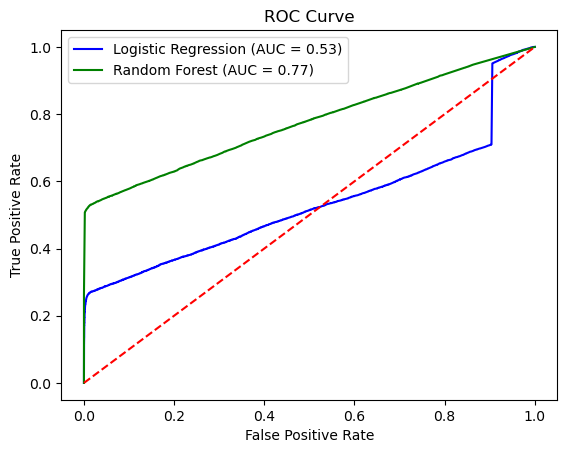

In [25]:
# Roc-auc analysis
from sklearn.metrics import roc_curve, auc
Y_prob = lr.predict_proba(X_test)[:, 1]
Y_prob_1 = classify.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(Y_test, Y_prob)
roc_auc = auc(fpr, tpr)
import matplotlib.pyplot as plt
fpr1, tpr1, _ = roc_curve(Y_test, Y_prob_1)
roc_auc1 = auc(fpr1, tpr1)
plt.figure()
plt.plot(fpr, tpr, color='blue', label='Logistic Regression (AUC = {:.2f})'.format(roc_auc))
plt.plot(fpr1, tpr1, color='green', label='Random Forest (AUC = {:.2f})'.format(roc_auc1))
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()  

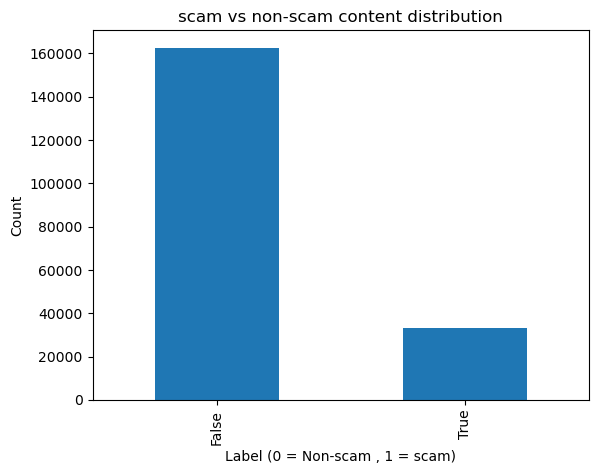

In [26]:
# Scam vs Non-scam distribution

import seaborn as sns
df_all['scam_likelihood'].value_counts().plot(kind='bar')
plt.title("scam vs non-scam content distribution")
plt.xlabel("Label (0 = Non-scam , 1 = scam)")
plt.ylabel("Count")
plt.show()

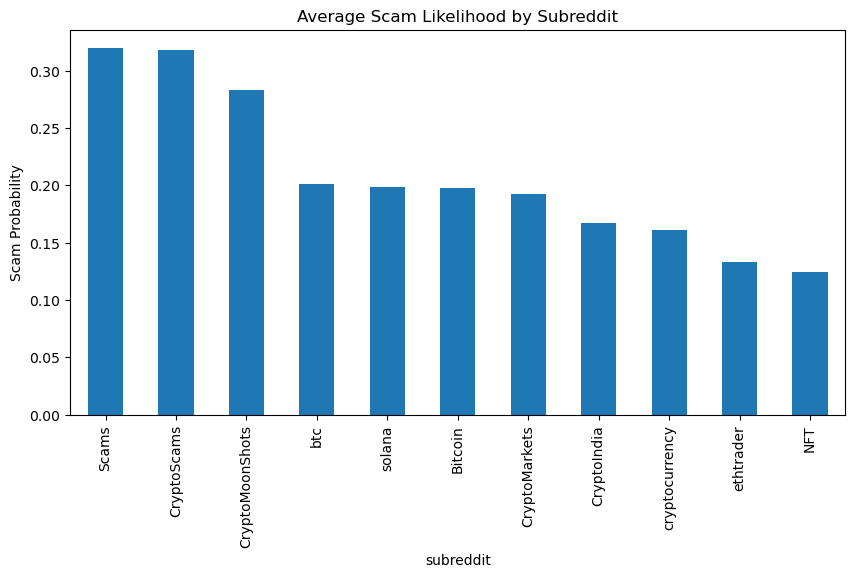

In [27]:
# Subreddit-wise Scam Density
subreddit_scam = df_all.groupby('subreddit')['scam_likelihood'].mean().sort_values(ascending=False)

subreddit_scam.plot(kind='bar', figsize=(10,5))
plt.title("Average Scam Likelihood by Subreddit")
plt.ylabel("Scam Probability")
plt.show()

In [28]:
from transformers import pipeline

# Drop-in replacement — same logic, much smaller model
zs_classifier = pipeline(
    "zero-shot-classification",
    model="cross-encoder/nli-MiniLM2-L6-H768",
    device=-1   # CPU
)

CANDIDATE_LABELS = ["cryptocurrency scam", "legitimate discussion"]

def bert_score(text_list, batch_size=64):   # can use bigger batch now
    scores = []
    for i in range(0, len(text_list), batch_size):
        batch = text_list[i : i + batch_size]
        batch = [str(t)[:512] for t in batch]
        results = zs_classifier(batch, CANDIDATE_LABELS)
        for res in results:
            idx = res["labels"].index("cryptocurrency scam")
            scores.append(res["scores"][idx])
        
        # Progress tracker so you know it's running
        if (i // batch_size) % 10 == 0:
            print(f"Processed {i}/{len(text_list)} posts...")
    
    return scores

df_all["bert_score"] = bert_score(df_all["text"].tolist())

Device set to use cpu
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA8626730> was reported to be 64(when accessing len(dataloader)), but 65 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA8626730> was reported to be 64(when accessing len(dataloader)), but 66 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA8626730> was reported to be 64(when accessing len(dataloader)), but 67 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\

Processed 0/195556 posts...


c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA8618610> was reported to be 64(when accessing len(dataloader)), but 65 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA8618610> was reported to be 64(when accessing len(dataloader)), but 66 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA8618610> was reported to be 64(when accessing len(dataloader)), but 67 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torc

Processed 640/195556 posts...


c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA98CCDF0> was reported to be 64(when accessing len(dataloader)), but 65 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA98CCDF0> was reported to be 64(when accessing len(dataloader)), but 66 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA98CCDF0> was reported to be 64(when accessing len(dataloader)), but 67 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torc

Processed 1280/195556 posts...


... (11 outputs left out)

Processed 66560/195556 posts...


c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA98D8D00> was reported to be 64(when accessing len(dataloader)), but 65 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA98D8D00> was reported to be 64(when accessing len(dataloader)), but 66 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA98D8D00> was reported to be 64(when accessing len(dataloader)), but 67 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torc

Processed 67200/195556 posts...
Processed 67840/195556 posts...
Processed 68480/195556 posts...
Processed 69120/195556 posts...
Processed 69760/195556 posts...
Processed 70400/195556 posts...
Processed 71040/195556 posts...
Processed 71680/195556 posts...
Processed 72320/195556 posts...
Processed 72960/195556 posts...
Processed 73600/195556 posts...
Processed 74240/195556 posts...
Processed 74880/195556 posts...
Processed 75520/195556 posts...
Processed 76160/195556 posts...
Processed 76800/195556 posts...
Processed 77440/195556 posts...
Processed 78080/195556 posts...
Processed 78720/195556 posts...
Processed 79360/195556 posts...
Processed 80000/195556 posts...
Processed 80640/195556 posts...
Processed 81280/195556 posts...
Processed 81920/195556 posts...
Processed 82560/195556 posts...
Processed 83200/195556 posts...
Processed 83840/195556 posts...
Processed 84480/195556 posts...
Processed 85120/195556 posts...
Processed 85760/195556 posts...
Processed 86400/195556 posts...
Processe

c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA98C6D90> was reported to be 36(when accessing len(dataloader)), but 37 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA98C6D90> was reported to be 36(when accessing len(dataloader)), but 38 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torch\utils\data\dataloader.py:718: UserWarning: Length of IterableDataset <transformers.pipelines.pt_utils.PipelineChunkIterator object at 0x0000028FA98C6D90> was reported to be 36(when accessing len(dataloader)), but 39 samples have been fetched. 
  warnings.warn(warn_msg)
c:\Users\User\anaconda3\lib\site-packages\torc

In [29]:
# Save only the score column — that's all that took 3-4 hours to compute
df_all[["bert_score"]].to_parquet("bert_scores.parquet", index=True)
print("✓ bert_score saved")

✓ bert_score saved


In [30]:
import pandas as pd

# Load scores back and merge onto df_all by index
saved_scores = pd.read_parquet("bert_scores.parquet")
df_all["bert_score"] = saved_scores["bert_score"]

print("✓ bert_score loaded — no inference needed")

✓ bert_score loaded — no inference needed


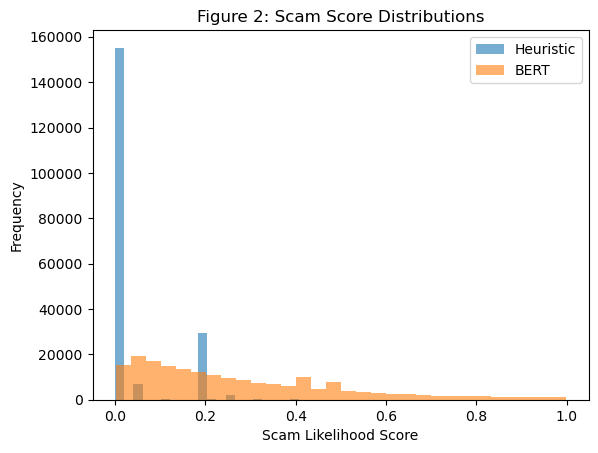

In [31]:
plt.figure()
plt.hist(df_all['scam_score'], bins=30, alpha=0.6, label="Heuristic")
plt.hist(df_all['bert_score'], bins=30, alpha=0.6, label="BERT")
# plt.hist(df_all['roberta_score'], bins=30, alpha=0.6, label="RoBERTa")

plt.xlabel("Scam Likelihood Score")
plt.ylabel("Frequency")
plt.legend()
plt.title("Figure 2: Scam Score Distributions")
plt.show()

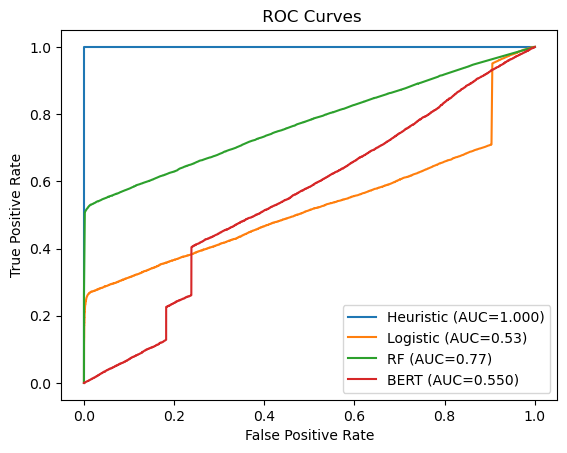

In [32]:
plt.figure()

# ensure df_test exists (rows corresponding to X_test)
df_test = df_all.loc[X_test.index]

# Heuristic
fpr_h, tpr_h, _ = roc_curve(Y_test, df_test['scam_score'])
plt.plot(fpr_h, tpr_h, label=f"Heuristic (AUC={auc(fpr_h,tpr_h):.3f})")

# Logistic
fpr_lr, tpr_lr, _ = roc_curve(Y_test, lr_probs)
plt.plot(fpr_lr, tpr_lr, label=f"Logistic (AUC={auc(fpr_lr,tpr_lr):.2f})")

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(Y_test, rf_probs)
plt.plot(fpr_rf, tpr_rf, label=f"RF (AUC={auc(fpr_rf,tpr_rf):.2f})")

# BERT
fpr_b, tpr_b, _ = roc_curve(Y_test, df_test['bert_score'])
plt.plot(fpr_b, tpr_b, label=f"BERT (AUC={auc(fpr_b,tpr_b):.3f})")


plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title(" ROC Curves")
plt.show()

In [33]:
temporal_df = df_all.groupby(df_all['timestamp_utc'].dt.to_period("H"))['scam_score'].mean()

In [34]:
from sklearn.ensemble import IsolationForest

# Use raw features to find outliers (potential 'novel' scams)
iso_forest = IsolationForest(contamination=0.05, random_state=42)
df_all['is_anomaly'] = iso_forest.fit_predict(df_all[FEATURES])

# Anomalies are marked as -1
novel_scams = df_all[df_all['is_anomaly'] == -1]
print(f"Detected {len(novel_scams)} anomalous posts that may be 'new' scam types.")

Detected 9778 anomalous posts that may be 'new' scam types.


In [35]:
# Regex patterns for common crypto addresses
eth_pattern = r'0x[a-fA-F0-0]{40}'
btc_pattern = r'[13][a-km-zA-HJ-NP-Z1-9]{25,34}'

def extract_wallets(text):
    wallets = re.findall(eth_pattern, text) + re.findall(btc_pattern, text)
    return list(set(wallets))

# Regex patterns for common crypto addresses
eth_pattern = r'0x[a-fA-F0-9]{40}'
btc_pattern = r'\b[13][a-km-zA-HJ-NP-Z1-9]{25,34}\b'

def extract_wallets(text):
    if not isinstance(text, str):
        return []
    wallets = re.findall(eth_pattern, text) + re.findall(btc_pattern, text)
    return list(set(wallets))

df_all['detected_wallets'] = df_all['text'].fillna('').astype(str).apply(extract_wallets)

unique_wallets = df_all[df_all['detected_wallets'].map(len) > 0]['detected_wallets'].explode().unique()
print(f"Found {len(unique_wallets)} unique crypto addresses for blacklisting.")

Found 549 unique crypto addresses for blacklisting.


In [36]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "distilroberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
).to("cpu")
for param in model.base_model.parameters():
    param.requires_grad = False

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at distilroberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [37]:
from datasets import Dataset

# Convert Period columns to string to avoid Arrow type error
for col in df_all.columns:
    if isinstance(df_all[col].dtype, pd.PeriodDtype):
        df_all[col] = df_all[col].astype(str)

# Ensure `text` has no missing values and is always string
df_all['text'] = df_all['text'].fillna('').astype(str)

# Convert pandas DataFrame → HuggingFace Dataset
# Convert object dtypes to strings to avoid Arrow conversion errors (e.g., mixed int/str in 'id')
for col in df_all.select_dtypes(include=['object']).columns:
    df_all[col] = df_all[col].fillna('').astype(str)

# Ensure label column is integer
if 'scam_likelihood' in df_all.columns:
    df_all['scam_likelihood'] = df_all['scam_likelihood'].fillna(0).astype(int)

# Build HuggingFace Dataset
dataset = Dataset.from_pandas(df_all.reset_index(drop=True))
dataset = dataset.train_test_split(test_size=0.3, seed=42)

def tokenize_function(examples):
    texts = [str(t) for t in examples["text"]]
    return tokenizer(
        texts,
        truncation=True,
        padding="max_length",
        max_length=128
    )

tokenized_dataset = dataset.map(tokenize_function, batched=True)
tokenized_dataset = tokenized_dataset.remove_columns(["text"])
tokenized_dataset = tokenized_dataset.map(
    lambda examples: {"labels": examples["scam_likelihood"]},
    batched=True
)

train_small = tokenized_dataset["train"].shuffle(seed=42).select(range(min(3000, len(tokenized_dataset["train"]))))
test_small = tokenized_dataset["test"].shuffle(seed=42).select(range(min(1000, len(tokenized_dataset["test"]))))


Map:   0%|          | 0/136889 [00:00<?, ? examples/s]

Map:   0%|          | 0/58667 [00:00<?, ? examples/s]

Map:   0%|          | 0/136889 [00:00<?, ? examples/s]

Map:   0%|          | 0/58667 [00:00<?, ? examples/s]

In [38]:
import sys
!{sys.executable} -m pip install --upgrade transformers accelerate

In [39]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from datasets import Dataset, Value
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score
)
import numpy as np
import torch
import pandas as pd

# ═══════════════════════════════════════════════════════════
# STEP 1 — Reload model cleanly with correct config
# ═══════════════════════════════════════════════════════════
MODEL_NAME = "distilroberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels        = 2,
    problem_type      = "single_label_classification",  # ← forces CrossEntropyLoss
)

# ── Unfreeze ALL layers so the model trains properly ───────
for param in model.parameters():
    param.requires_grad = True

print(f"Model loaded: {MODEL_NAME}")
print(f"Problem type: {model.config.problem_type}")
print(f"Num labels  : {model.config.num_labels}")


# ═══════════════════════════════════════════════════════════
# STEP 2 — Rebuild datasets cleanly
# ═══════════════════════════════════════════════════════════

# Convert Period columns to string (Arrow doesn't support Period)
df_copy = df_all.copy()
for col in df_copy.columns:
    if hasattr(df_copy[col], 'dt') and hasattr(df_copy[col].dt, 'to_timestamp'):
        df_copy[col] = df_copy[col].astype(str)
    elif str(df_copy[col].dtype) == 'period[M]':
        df_copy[col] = df_copy[col].astype(str)

# Only keep the two columns we need
df_model = df_copy[['text', 'scam_likelihood']].copy()
df_model['labels'] = df_model['scam_likelihood'].astype(int)
df_model = df_model[['text', 'labels']].dropna()

# Build HuggingFace dataset
dataset = Dataset.from_pandas(df_model, preserve_index=False)

# Cast labels to int64 explicitly
dataset = dataset.cast_column("labels", Value("int64"))

# Train / test split
dataset = dataset.train_test_split(test_size=0.3, seed=42)

# Tokenize
def tokenize(examples):
    return tokenizer(
        examples["text"],
        truncation = True,
        padding    = "max_length",
        max_length = 128
    )

tokenized = dataset.map(tokenize, batched=True)

# Remove raw text column — keep only model inputs + labels
keep_cols = tokenizer.model_input_names + ["labels"]
tokenized = tokenized.remove_columns(
    [c for c in tokenized["train"].column_names if c not in keep_cols]
)

# Set torch format
tokenized["train"].set_format(type="torch", columns=keep_cols)
tokenized["test"].set_format(type="torch",  columns=keep_cols)

# Subsample for speed
train_small = tokenized["train"].shuffle(seed=42).select(range(3000))
test_small  = tokenized["test"].shuffle(seed=42).select(range(1000))

# ── Verify labels are correct ──────────────────────────────
sample = train_small[0]
print(f"\nLabel dtype : {sample['labels'].dtype}")   # must be torch.int64
print(f"Label value : {sample['labels'].item()}")    # must be 0 or 1
print(f"Input IDs   : {sample['input_ids'].shape}")  # must be torch.Size([128])


# ═══════════════════════════════════════════════════════════
# STEP 3 — Metrics
# ═══════════════════════════════════════════════════════════
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds          = np.argmax(logits, axis=1)
    acc            = accuracy_score(labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary", zero_division=0
    )
    probs = torch.softmax(torch.tensor(logits, dtype=torch.float32), dim=1)[:, 1].numpy()
    auc   = roc_auc_score(labels, probs)
    return {
        "accuracy":  round(acc,       4),
        "precision": round(precision, 4),
        "recall":    round(recall,    4),
        "f1":        round(f1,        4),
        "roc_auc":   round(auc,       4)
    }


# ═══════════════════════════════════════════════════════════
# STEP 4 — Train
# ═══════════════════════════════════════════════════════════

import inspect

eval_arg_name = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters else "evaluation_strategy"

training_args = TrainingArguments(
    output_dir                  = "./fast_roberta",
    per_device_train_batch_size = 8,
    per_device_eval_batch_size  = 8,
    num_train_epochs            = 2,
    no_cuda                     = True,
    report_to                   = "none",
    save_strategy               = "no",
    logging_steps               = 50,
    warmup_steps                = 100,
    weight_decay                = 0.01,
    **{eval_arg_name: "epoch"}
)
# training_args = TrainingArguments(
#     output_dir                  = "./fast_roberta",
#     per_device_train_batch_size = 8,
#     per_device_eval_batch_size  = 8,
#     num_train_epochs            = 2,
#     no_cuda                     = True,
#     report_to                   = "none",
#     evaluation_strategy         = "epoch",
#     save_strategy               = "no",
#     logging_steps               = 50,
#     warmup_steps                = 100,
#     weight_decay                = 0.01,
# )

trainer = Trainer(
    model           = model,
    args            = training_args,
    train_dataset   = train_small,
    eval_dataset    = test_small,
    compute_metrics = compute_metrics
)

trainer.train()

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at distilroberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded: distilroberta-base
Problem type: single_label_classification
Num labels  : 2


Casting the dataset:   0%|          | 0/195556 [00:00<?, ? examples/s]

Map:   0%|          | 0/136889 [00:00<?, ? examples/s]

Map:   0%|          | 0/58667 [00:00<?, ? examples/s]


Label dtype : torch.int64
Label value : 0
Input IDs   : torch.Size([128])


c:\Users\User\anaconda3\lib\site-packages\transformers\training_args.py:1636: FutureWarning: using `no_cuda` is deprecated and will be removed in version 5.0 of 🤗 Transformers. Use `use_cpu` instead
  warnings.warn(
c:\Users\User\anaconda3\lib\site-packages\torch\cuda\__init__.py:905: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 11070). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\c10\cuda\CUDAFunctions.cpp:108.)
  r = torch._C._cuda_getDeviceCount() if nvml_count < 0 else nvml_count


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,0.360400,0.337364,0.894000,0.902900,0.492100,0.637000,0.735400
2,0.277600,0.346175,0.899000,0.949000,0.492100,0.648100,0.746600


TrainOutput(global_step=750, training_loss=0.36473304494222003, metrics={'train_runtime': 617.8966, 'train_samples_per_second': 9.71, 'train_steps_per_second': 1.214, 'total_flos': 198701097984000.0, 'train_loss': 0.36473304494222003, 'epoch': 2.0})

In [40]:
inference_dataset = Dataset.from_pandas(df_all)

inference_dataset = inference_dataset.map(
    tokenize_function,
    batched=True
)

inference_dataset = inference_dataset.remove_columns(
    [col for col in inference_dataset.column_names if col not in tokenizer.model_input_names]
)
predictions = trainer.predict(inference_dataset)
logits = predictions.predictions
probs = torch.softmax(torch.tensor(logits), dim=1)[:, 1].numpy()
df_all['roberta_score'] = probs

Map:   0%|          | 0/195556 [00:00<?, ? examples/s]

In [41]:
# Run this once after both score columns exist in df_all
df_all[["bert_score", "roberta_score"]].to_parquet("all_scores.parquet", index=True)
print("✓ Both scores saved")

✓ Both scores saved


In [42]:
saved = pd.read_parquet("all_scores.parquet")
df_all["bert_score"]    = saved["bert_score"]
df_all["roberta_score"] = saved["roberta_score"]

In [43]:
df_all.groupby("year_month")[["heuristic_score", "bert_score", "roberta_score"]].mean()

,heuristic_score,bert_score,roberta_score
year_month,,,
2017-01,0.140000,0.448757,0.110140
2017-02,0.290837,0.420525,0.176096
2017-03,0.086207,0.388661,0.129473
2017-04,0.155125,0.354113,0.194101
2017-05,0.186275,0.405790,0.201097
...,...,...,...
2025-08,0.137363,0.253554,0.159147
2025-09,0.149351,0.252784,0.243665
2025-10,0.044049,0.283133,0.162793


In [44]:
df_all[['heuristic_score', 'bert_score', 'roberta_score']].describe()

,heuristic_score,bert_score,roberta_score
count,195556.000000,195556.000000,195556.000000
mean,0.057641,0.277297,0.136340
std,0.266188,0.226414,0.265541
min,0.000000,0.000974,0.040547
25%,0.000000,0.094592,0.050682
50%,0.000000,0.215138,0.053062
75%,0.000000,0.405267,0.056186
max,7.000000,0.998455,0.996722


In [45]:
descriptive_stats = (
    df_all
    .groupby("source")
    .agg(
        Total_Messages=("text", "count"),
        Avg_RoBERTa_Score=("roberta_score", "mean"),
        Avg_BERT_Score=("bert_score", "mean")
    )
    .round(3)
    .reset_index()
    .rename(columns={"source": "Scam Type"})
)

descriptive_stats

,Scam Type,Total_Messages,Avg_RoBERTa_Score,Avg_BERT_Score
0,Celsius,68101,0.142,0.270
1,Centra,2946,0.164,0.292
2,FTX,117124,0.132,0.277
3,OneCoin,7385,0.139,0.342


In [46]:
order = ["Celsius", "Centra", "FTX", "OneCoin"]
descriptive_stats["Scam Type"] = pd.Categorical(descriptive_stats["Scam Type"], categories=order, ordered=True)
descriptive_stats = descriptive_stats.sort_values("Scam Type").reset_index(drop=True)
descriptive_stats

,Scam Type,Total_Messages,Avg_RoBERTa_Score,Avg_BERT_Score
0,Celsius,68101,0.142,0.270
1,Centra,2946,0.164,0.292
2,FTX,117124,0.132,0.277
3,OneCoin,7385,0.139,0.342


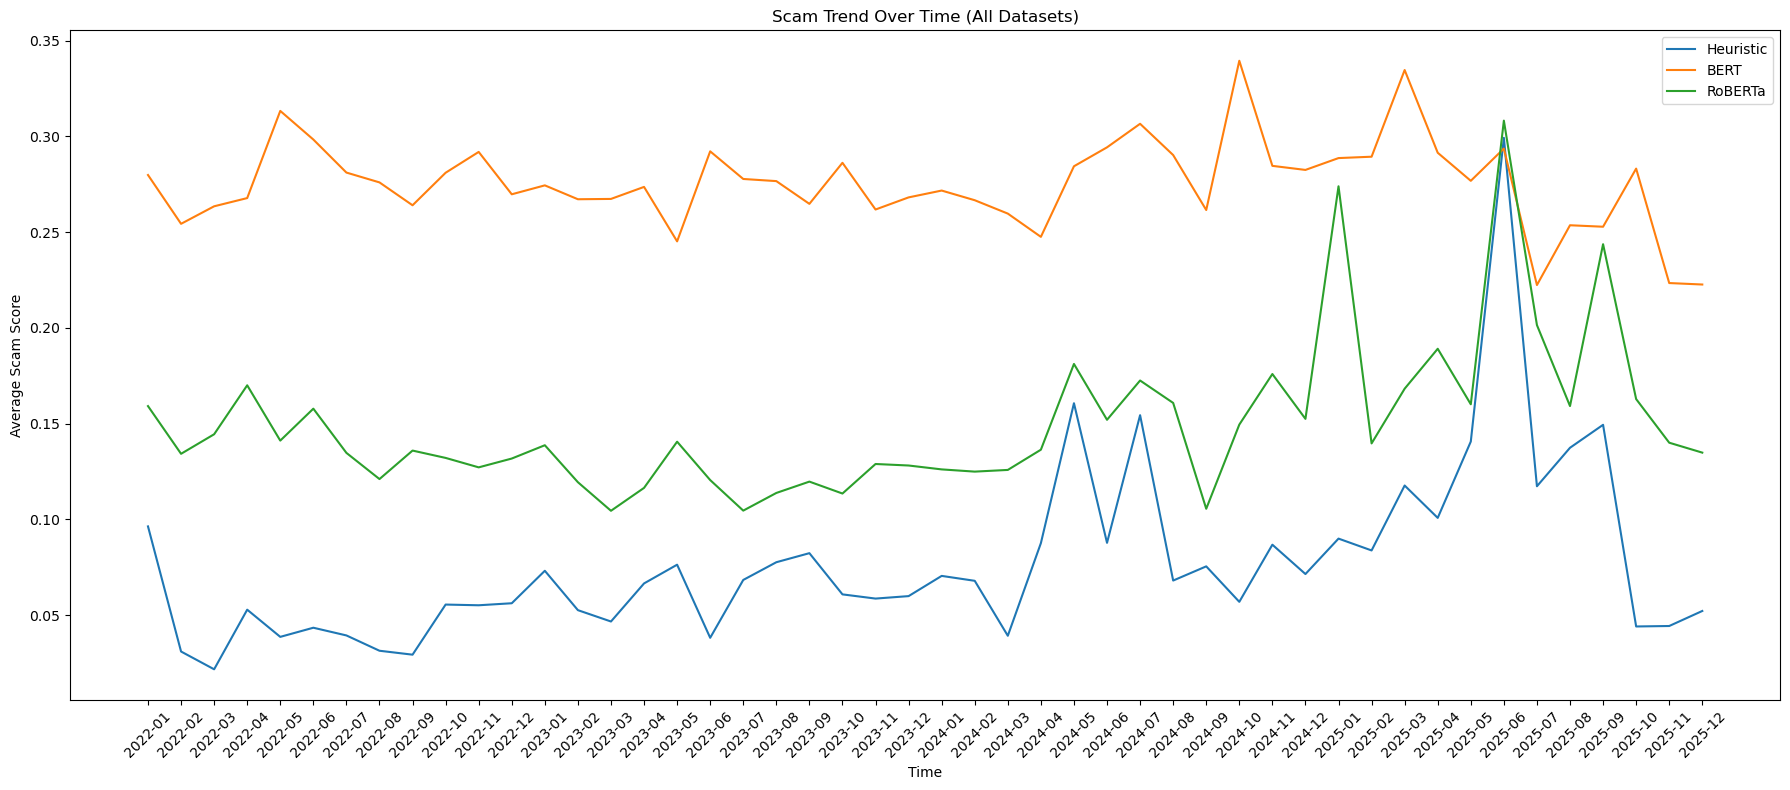

In [47]:
# trend_df = df_all.groupby('year_month').agg(
#     total_msgs=('text', 'count'),
#     heuristic_avg=('heuristic_score', 'mean'),
#     bert_avg=('bert_score', 'mean'),
#     roberta_avg=('roberta_score', 'mean')
# ).reset_index()

# trend_df['year_month'] = trend_df['year_month'].astype(str)
trend_df = df_all.groupby('year_month').agg(
    total_msgs=('text', 'count'),
    heuristic_avg=('heuristic_score', 'mean'),
    bert_avg=('bert_score', 'mean'),
    roberta_avg=('roberta_score', 'mean')
).reset_index()

trend_df['year_month'] = trend_df['year_month'].astype(str)

# Filter to 2022 onward
trend_df_filtered = trend_df[trend_df['year_month'].astype(str) >= "2022-01"].copy()

x_labels = trend_df_filtered['year_month'].astype(str)


plt.figure(figsize=(18,8))
plt.plot(x_labels, trend_df_filtered['heuristic_avg'], label='Heuristic')
plt.plot(x_labels, trend_df_filtered['bert_avg'], label='BERT')
plt.plot(x_labels, trend_df_filtered['roberta_avg'], label='RoBERTa')

plt.xticks(rotation=45)
plt.xlabel("Time")
plt.ylabel("Average Scam Score")
plt.title("Scam Trend Over Time (All Datasets)")
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
# Define predictions using a threshold (e.g., 0.5)
heuristic_pred = (df_all['heuristic_score'] >= 2)  # as in your earlier heuristic_label
bert_pred = (df_all['bert_score'] > 0.5)
roberta_pred = (df_all['roberta_score'] > 0.5)

combined_analysis = pd.DataFrame({
    'Model': ['Heuristic', 'BERT', 'RoBERTa'],
    'Mean Scam Score': [
        df_all['heuristic_score'].mean(),
        df_all['bert_score'].mean(),
        df_all['roberta_score'].mean()
    ],
    'Score Std Dev': [
        df_all['heuristic_score'].std(),
        df_all['bert_score'].std(),
        df_all['roberta_score'].std()
    ],
    'Scam Rate (%)': [
        heuristic_pred.mean() * 100,
        bert_pred.mean() * 100,
        roberta_pred.mean() * 100
    ]
})

combined_analysis

,Model,Mean Scam Score,Score Std Dev,Scam Rate (%)
0,Heuristic,0.057641,0.266188,0.424942
1,BERT,0.277297,0.226414,15.488658
2,RoBERTa,0.136340,0.265541,8.920718


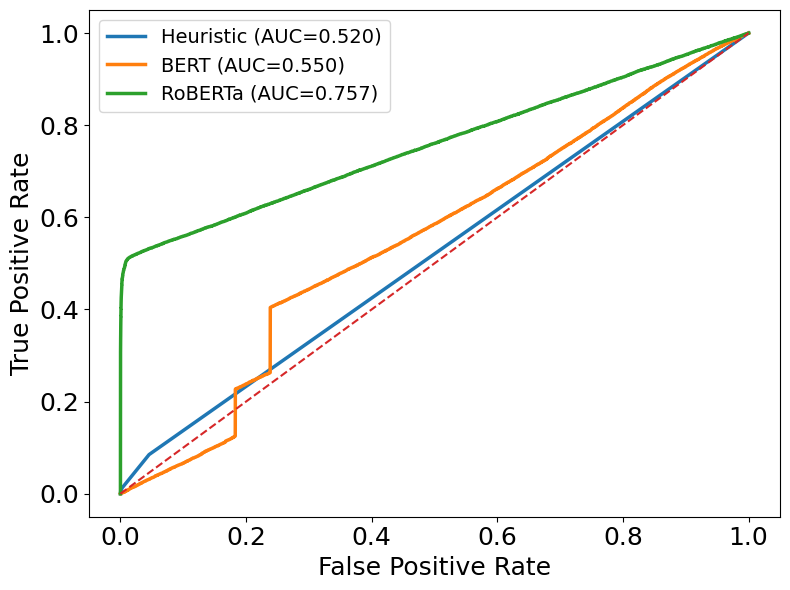

In [49]:
from sklearn.metrics import roc_curve, auc


plt.figure(figsize=(8,6))

LINE_WIDTH = 2.5
LABEL_SIZE = 18
TICK_SIZE = 18
LEGEND_SIZE = 14
TITLE_SIZE = 18

# Heuristic
fpr_h, tpr_h, _ = roc_curve(df_all['scam_likelihood'], df_all['heuristic_score'])
plt.plot(fpr_h, tpr_h, linewidth=LINE_WIDTH,
         label=f"Heuristic (AUC={auc(fpr_h, tpr_h):.3f})")

# BERT
fpr_b, tpr_b, _ = roc_curve(df_all['scam_likelihood'], df_all['bert_score'])
plt.plot(fpr_b, tpr_b, linewidth=LINE_WIDTH,
         label=f"BERT (AUC={auc(fpr_b, tpr_b):.3f})")

# RoBERTa
fpr_r, tpr_r, _ = roc_curve(df_all['scam_likelihood'], df_all['roberta_score'])
plt.plot(fpr_r, tpr_r, linewidth=LINE_WIDTH,
         label=f"RoBERTa (AUC={auc(fpr_r, tpr_r):.3f})")

# Random baseline
plt.plot([0,1], [0,1], linestyle='--', linewidth=1.5)

# Labels
plt.xlabel("False Positive Rate", fontsize=LABEL_SIZE)
plt.ylabel("True Positive Rate", fontsize=LABEL_SIZE)
# plt.title("ROC Curve Comparison", fontsize=TITLE_SIZE)

# Tick sizes
plt.xticks(fontsize=TICK_SIZE)
plt.yticks(fontsize=TICK_SIZE)

# Legend
plt.legend(fontsize=LEGEND_SIZE)

plt.tight_layout()
plt.show()


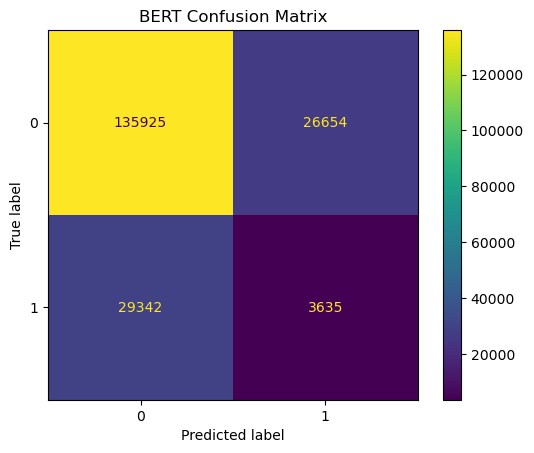

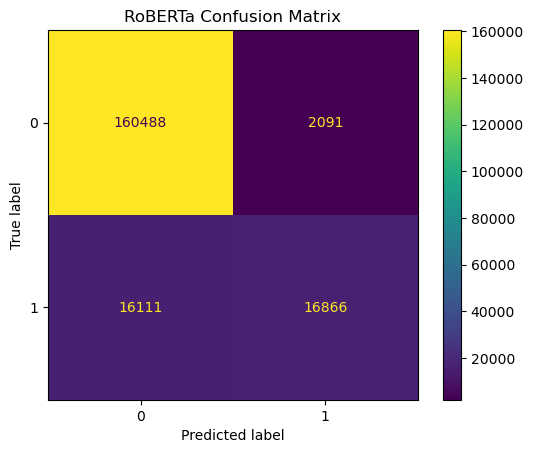

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve

true_label = df_all['scam_likelihood'].astype(int)
fpr, tpr, thresholds = roc_curve(true_label, df_all['roberta_score'])
best_threshold = thresholds[np.argmax(tpr - fpr)]


# Prepare predictions and true labels
bert_pred = (df_all['bert_score'] > 0.5).astype(int)
# roberta_pred = (df_all['roberta_score'] > 0.5).astype(int)
roberta_pred = (df_all['roberta_score'] >= best_threshold).astype(int)

# BERT
cm_bert = confusion_matrix(true_label, bert_pred)
ConfusionMatrixDisplay(cm_bert).plot()
plt.title("BERT Confusion Matrix")
plt.show()

# RoBERTa
cm_roberta = confusion_matrix(true_label, roberta_pred)
ConfusionMatrixDisplay(cm_roberta).plot()
plt.title("RoBERTa Confusion Matrix")
plt.show()


In [51]:
from sklearn.metrics import precision_score, recall_score, f1_score
def compute_metrics(y_true, y_pred):
    return {
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }
metrics_heuristic = compute_metrics(true_label, heuristic_pred)
metrics_bert = compute_metrics(true_label, bert_pred)
metrics_roberta = compute_metrics(true_label, roberta_pred)
import pandas as pd

metrics_df = pd.DataFrame.from_dict(
    {
        "Heuristic": metrics_heuristic,
        "BERT": metrics_bert,
        "RoBERTa": metrics_roberta
    },
    orient="index"
)

metrics_df
# metrics_df.round(4).to_latex()


,Precision,Recall,F1-score
Heuristic,0.490975,0.012372,0.024136
BERT,0.120011,0.110228,0.114912
RoBERTa,0.889698,0.511447,0.649517


In [79]:
# Re-create df_24_25 to ensure 'roberta_score' exists
df_24_25 = df_all[df_all['year'].isin([2022, 2023, 2024, 2025])]

severity_24_25 = (
    df_24_25
    .groupby(['year_month', 'source'])
    .agg(avg_roberta_score=('roberta_score', 'mean'))
    .reset_index()
)

severity_24_25['year_month'] = severity_24_25['year_month'].astype(str)

In [80]:
severity_24_25 = severity_24_25.sort_values(["source", "year_month"])

severity_24_25["roberta_smooth"] = (
    severity_24_25
    .groupby("source")["avg_roberta_score"]
    .transform(lambda x: x.rolling(window=3, min_periods=1).mean())
)

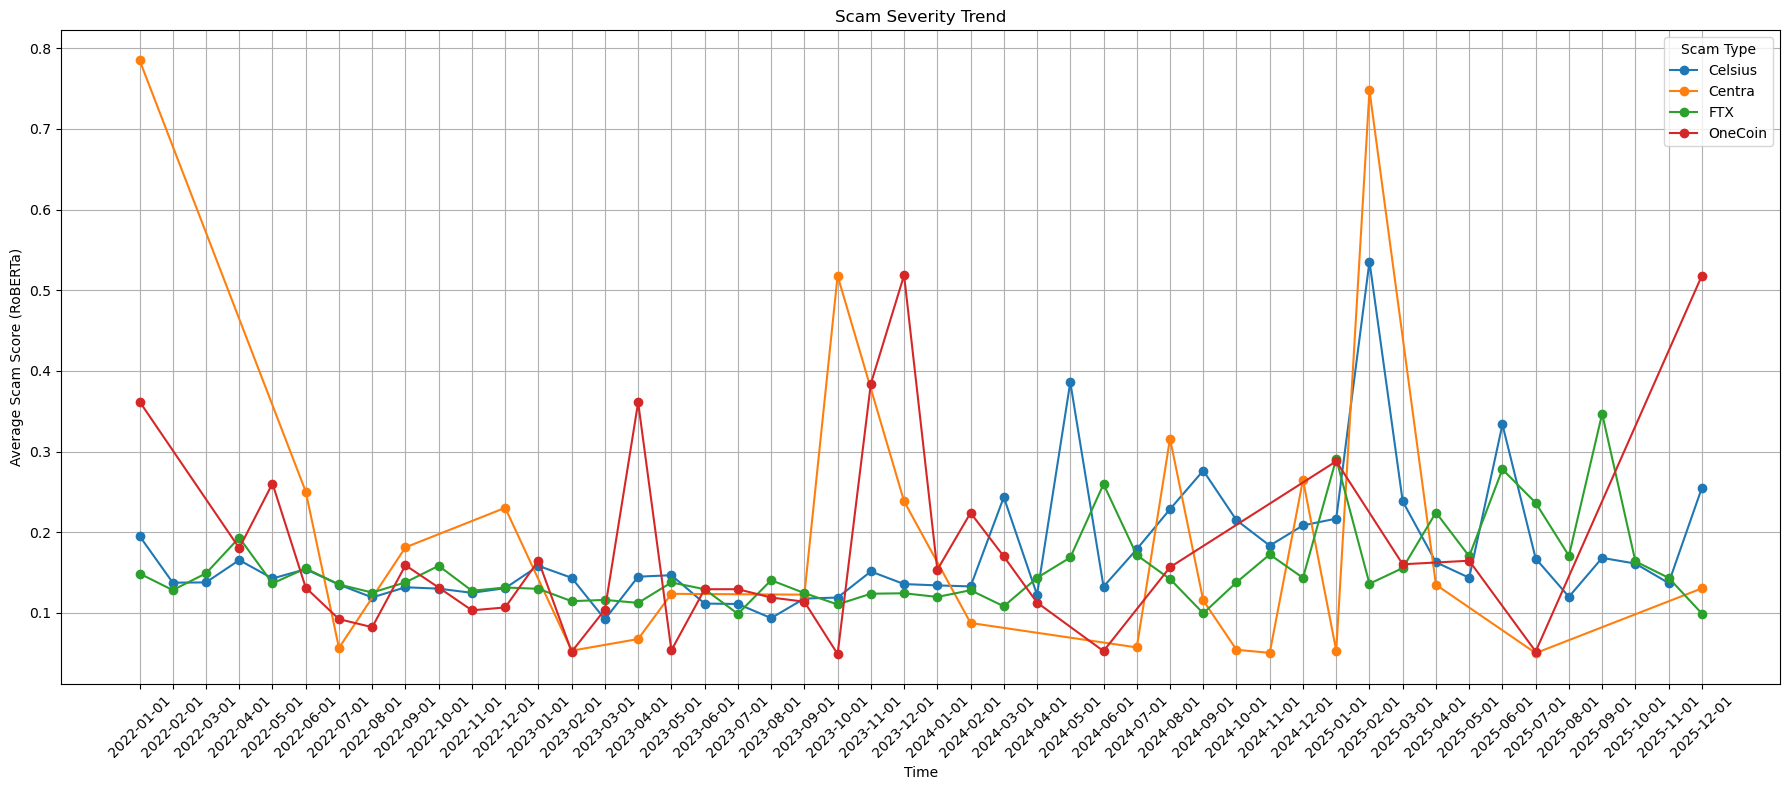

In [81]:
plt.figure(figsize=(18, 8))

LINE_WIDTH = 2.5
LABEL_SIZE = 20
TICK_SIZE = 20
LEGEND_SIZE = 18
TITLE_SIZE = 18
MARKER_SIZE = 8
for scam in severity_24_25['source'].unique():
    temp = severity_24_25[severity_24_25['source'] == scam]
    plt.plot(
        temp['year_month'],
        temp['avg_roberta_score'],
        marker='o',
        label=scam
    )


plt.xlabel("Time")
plt.ylabel("Average Scam Score (RoBERTa)")
plt.title("Scam Severity Trend")
plt.xticks(rotation=45)
plt.legend(title="Scam Type")
plt.grid(True)
plt.tight_layout()
plt.show()

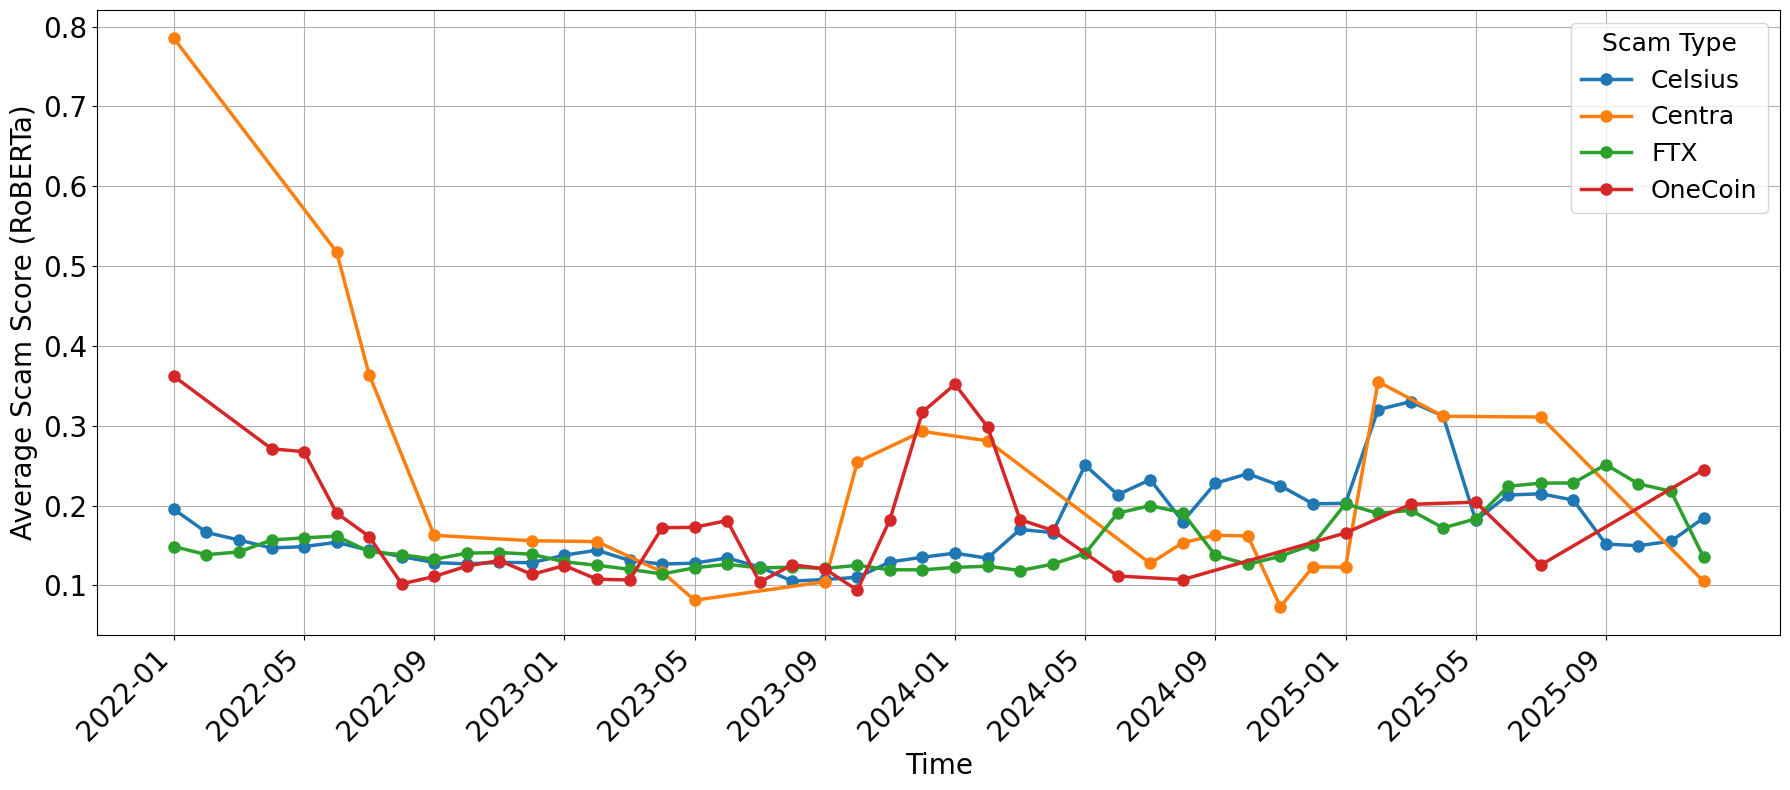

In [82]:
plt.figure(figsize=(18, 8))

LINE_WIDTH = 2.5
LABEL_SIZE = 20
TICK_SIZE = 20
LEGEND_SIZE = 18
TITLE_SIZE = 18
MARKER_SIZE = 8



for scam in severity_24_25['source'].unique():
    temp = severity_24_25[severity_24_25['source'] == scam]
    plt.plot(
        temp['year_month'],
        temp['roberta_smooth'],
        marker='o',
        linewidth=LINE_WIDTH,
        markersize=MARKER_SIZE,
        label=scam
    )

ax = plt.gca()
tick_positions = range(0, len(x_labels), 4)   # every 2nd month; use 3 for even sparser
ax.set_xticks(tick_positions)
ax.set_xticklabels(x_labels.iloc[tick_positions], rotation=45, ha="right", fontsize=TICK_SIZE)

plt.xlabel("Time", fontsize=LABEL_SIZE)
plt.ylabel("Average Scam Score (RoBERTa)", fontsize=LABEL_SIZE)
# plt.title("Scam Severity Trend", fontsize=TITLE_SIZE)

plt.xticks(rotation=45, fontsize=TICK_SIZE)
plt.yticks(fontsize=TICK_SIZE)

plt.legend(title="Scam Type", fontsize=LEGEND_SIZE, title_fontsize=LEGEND_SIZE)

plt.grid(True)
plt.tight_layout()
plt.show()



In [56]:
# NORMALIZE heuristic score to [0,1] range
df_all["heuristic_prob"] = (
    df_all["heuristic_score"] / df_all["heuristic_score"].max()
)

In [57]:
monthly_trend = (
    df_all
    .groupby("year_month")[["heuristic_prob", "bert_score", "roberta_score"]]
    .mean()
    .reset_index()
    .sort_values("year_month")
)

In [58]:
monthly_growth = monthly_trend.copy()

monthly_growth[["heuristic_growth_%", "bert_growth_%", "roberta_growth_%"]] = (
    monthly_trend[["heuristic_prob", "bert_score", "roberta_score"]]
    .pct_change(periods=12) * 100
)

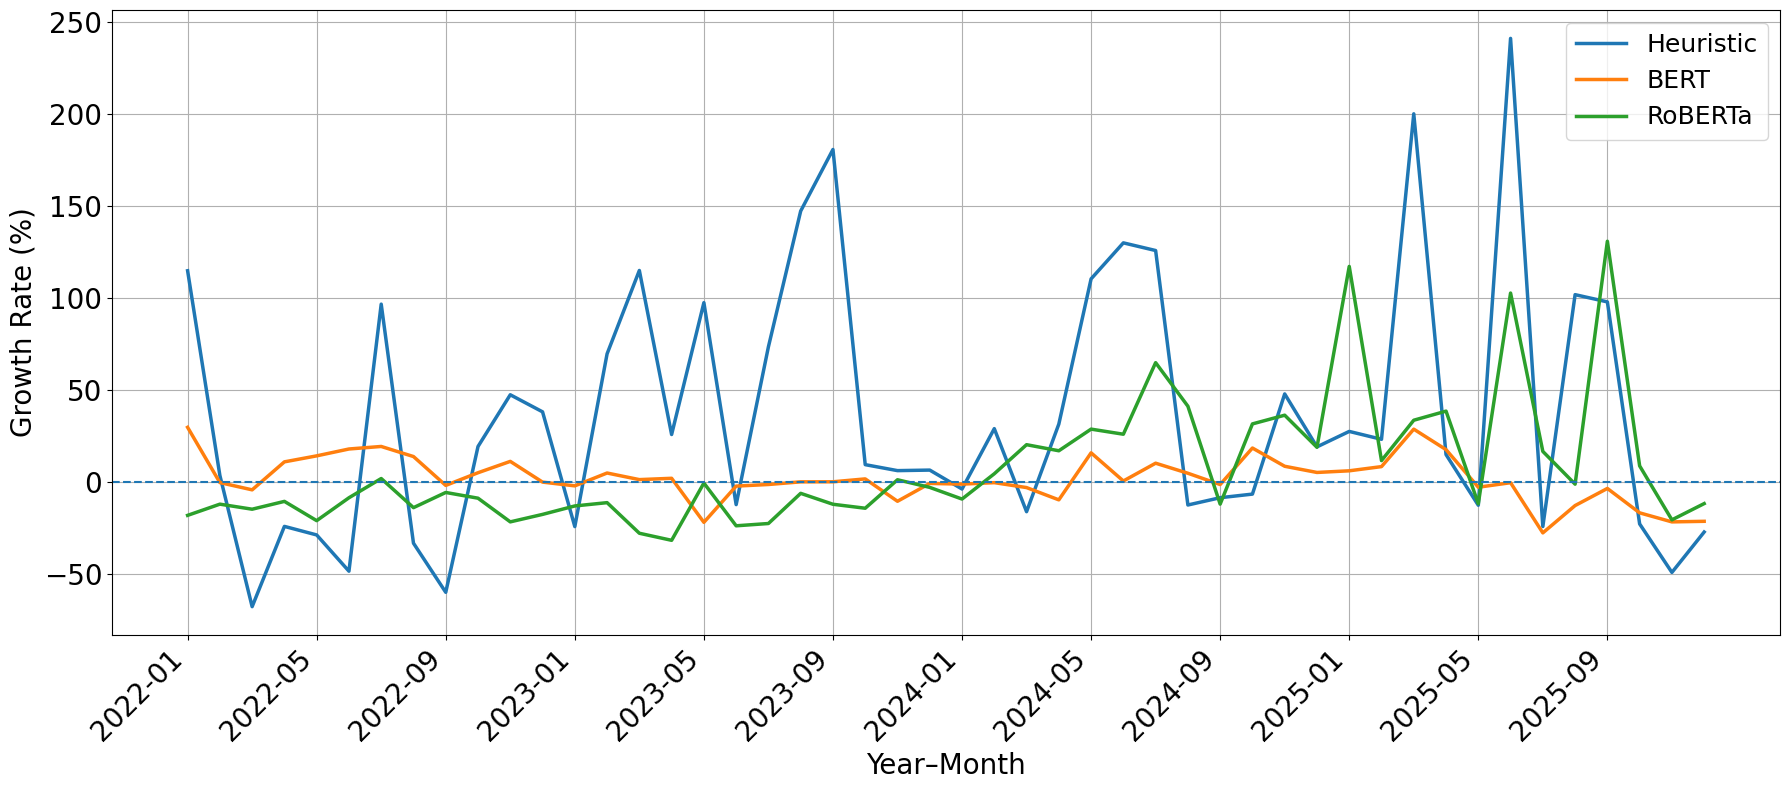

In [59]:

plt.figure(figsize=(18, 8))

LINE_WIDTH = 2.5
LABEL_SIZE = 20
TICK_SIZE = 20
LEGEND_SIZE = 18
TITLE_SIZE = 18

# Filter to 2022 onward
monthly_growth_filtered = monthly_growth[
    monthly_growth["year_month"].astype(str) >= "2022-01"
].copy()

x_labels = monthly_growth_filtered["year_month"].astype(str)

plt.plot(
    x_labels,
    monthly_growth_filtered["heuristic_growth_%"],
    linewidth=LINE_WIDTH,
    label="Heuristic"
)

plt.plot(
    x_labels,
    monthly_growth_filtered["bert_growth_%"],
    linewidth=LINE_WIDTH,
    label="BERT"
)

plt.plot(
    x_labels,
    monthly_growth_filtered["roberta_growth_%"],
    linewidth=LINE_WIDTH,
    label="RoBERTa"
)

plt.axhline(0, linestyle="--", linewidth=1.5)

# Show every 2nd (or 3rd) tick label to avoid overlap
ax = plt.gca()
tick_positions = range(0, len(x_labels), 4)   # every 2nd month; use 3 for even sparser
ax.set_xticks(tick_positions)
ax.set_xticklabels(x_labels.iloc[tick_positions], rotation=45, ha="right", fontsize=TICK_SIZE)

plt.yticks(fontsize=TICK_SIZE)

plt.xlabel("Year–Month", fontsize=LABEL_SIZE)
plt.ylabel("Growth Rate (%)", fontsize=LABEL_SIZE)

plt.legend(fontsize=LEGEND_SIZE)
plt.grid(True, linewidth=0.8)

plt.tight_layout()
plt.show()


In [60]:
# Aggregate yearly RoBERTa score
yearly_trend = (
    df_all
    .groupby("year")["roberta_score"]
    .mean()
    .sort_index()
)

start_value = yearly_trend.iloc[0]
end_value   = yearly_trend.iloc[-1]
num_years   = yearly_trend.index[-1] - yearly_trend.index[0]

cagr = (end_value / start_value) ** (1 / num_years) - 1

print(f"Overall Scam CAGR (RoBERTa): {cagr * 100:.2f}%")
# CAGR > 0 → long-term increase in scam activity

# CAGR < 0 → declining trend


Overall Scam CAGR (RoBERTa): -0.61%


In [61]:
pd.DataFrame({
    "Start Year": [yearly_trend.index[0]],
    "End Year": [yearly_trend.index[-1]],
    "CAGR (%)": [cagr * 100]
})


,Start Year,End Year,CAGR (%)
0,2017,2025,-0.610823


In [62]:
scam_monthly = (
    df_all
    .groupby(["year_month", "source"])["roberta_score"]
    .mean()
    .reset_index()
    .sort_values(["source", "year_month"])
)
# scam_monthly["growth_rate_%"] = (
#     scam_monthly
#     .groupby("source")["roberta_score"]
#     .transform(lambda x: (x / x.iloc[0]) * 100)
# )
scam_monthly["smooth_score"] = (
    scam_monthly
    .groupby("source")["roberta_score"]
    .transform(lambda x: x.rolling(window=3, min_periods=1).mean())
)

scam_monthly["growth_rate_%"] = (
    scam_monthly
    .groupby("source")["smooth_score"]
    .pct_change() * 100
)

# Remove first value for each scam
scam_monthly.loc[
    scam_monthly.groupby("source").head(1).index,
    "growth_rate_%"
] = np.nan


In [63]:
# monthly_count = (
#     df_all
#     .groupby(["year_month", "source"])
#     .size()
#     .reset_index(name="count")
# )

# scam_monthly = scam_monthly.merge(
#     monthly_count,
#     on=["year_month", "source"]
# )

# # Remove months with fewer than 5 posts
# scam_monthly = scam_monthly[
#     scam_monthly["count"] >= 5
# ]

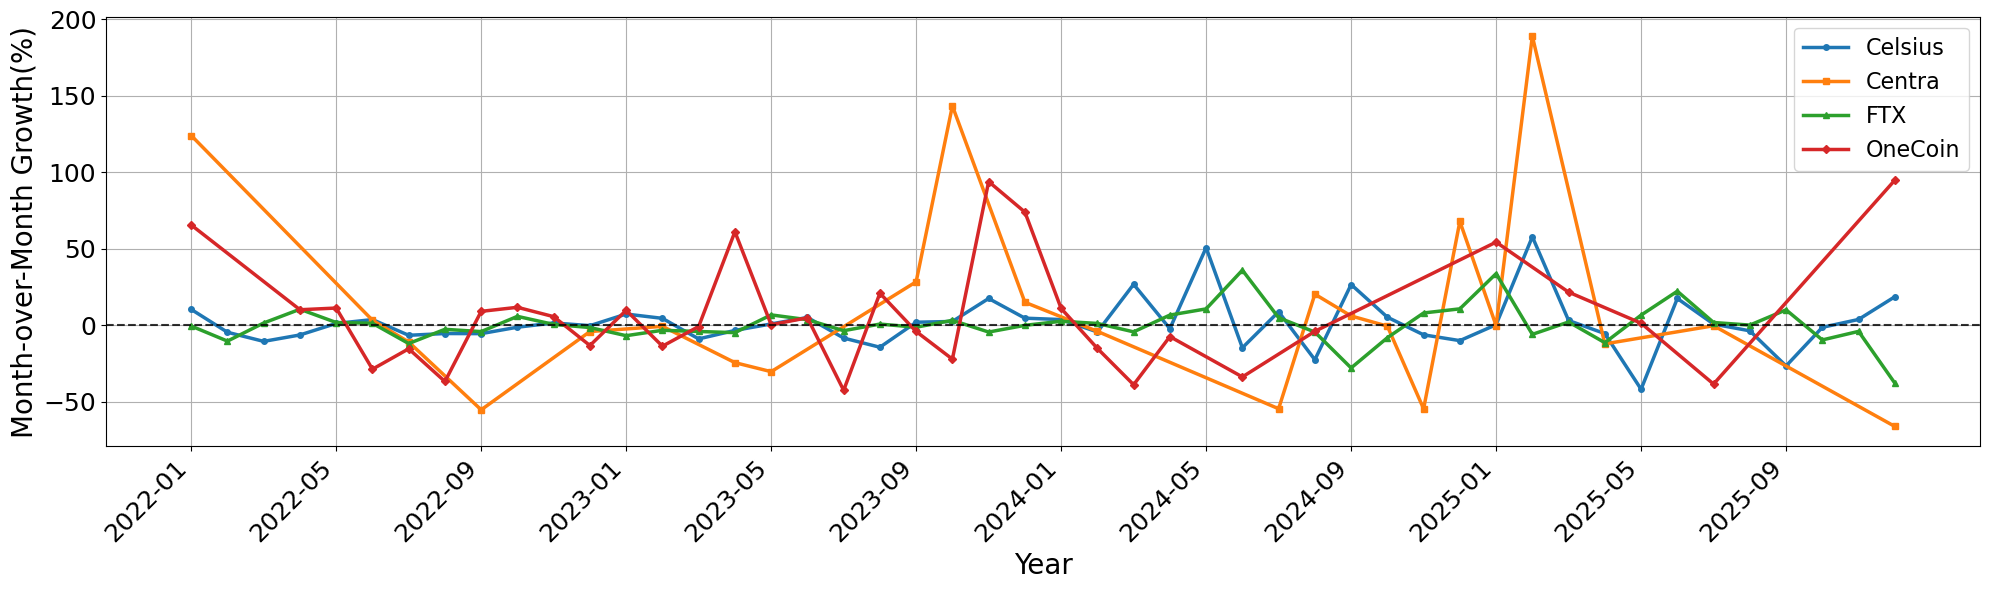

In [87]:

plt.figure(figsize=(20, 6))

LINE_WIDTH = 2.5
LABEL_SIZE = 20
TICK_SIZE = 18
LEGEND_SIZE = 16
TITLE_SIZE = 16
MARKER_SIZE = 4

monthly_growth_filtered = scam_monthly[
    scam_monthly["year_month"].astype(str) >= "2022-01"
].copy()

x_label = monthly_growth_filtered["year_month"].astype(str)
markers = {
    "Celsius": "o",
    "Centra": "s",
    "FTX": "^",
    "OneCoin": "D"
}
for scam in scam_monthly["source"].unique():
    subset = scam_monthly[scam_monthly["source"] == scam]
    subset = subset[
        subset["year_month"].astype(str) >= "2022-01"
    ].sort_values("year_month")

    plt.plot(
        subset["year_month"].astype(str),
        subset["growth_rate_%"],
        marker=markers[scam],
        linewidth=LINE_WIDTH,
        markersize=MARKER_SIZE,
        label=scam
    )

plt.axhline(0, linestyle="--", linewidth=1.5, color ="black", alpha=0.8)

# Show x-axis ticks every 6 months
all_months = sorted(x_label.unique())
tick_positions = range(0, len(all_months), 4)

ax = plt.gca()
ax.set_xticks(tick_positions)
ax.set_xticklabels([all_months[i] for i in tick_positions], rotation=45, ha="right", fontsize=TICK_SIZE)

plt.yticks(fontsize=TICK_SIZE)

plt.xlabel("Year", fontsize=LABEL_SIZE)
plt.ylabel("Month-over-Month Growth(%)", fontsize=LABEL_SIZE)

plt.legend(fontsize=LEGEND_SIZE)
plt.grid(True, linewidth=0.8)

plt.tight_layout()
plt.show()

In [65]:
df_all['year_month'] = pd.to_datetime(df_all['year_month'], format='%Y-%m')

df_all['year_month'].dtype


dtype('<M8[ns]')

In [66]:
cagr_per_scam = []

for scam in df_all["source"].unique():
    temp = (
        df_all[df_all["source"] == scam]
        .groupby("year_month")["roberta_score"]
        .mean()
        .sort_index()
    )

    if len(temp) > 1:
        start = temp.iloc[0]
        end = temp.iloc[-1]

        # Total number of months between first and last entry
        months = (temp.index[-1].year - temp.index[0].year) * 12 + \
                 (temp.index[-1].month - temp.index[0].month)

        if months > 0 and start > 0:
            scam_cagr = (end / start) ** (1 / months) - 1
            cagr_per_scam.append([scam, scam_cagr * 100])

cagr_df = pd.DataFrame(cagr_per_scam, columns=["Scam", "CAGR (%)"])
cagr_df

,Scam,CAGR (%)
0,OneCoin,1.457542
1,FTX,0.750892
2,Centra,-0.432748
3,Celsius,0.494428
